# Example: YAML/folder-driven decay-chain transport simulation

A one-dimensional, decay-chain (Cm-247, Am-243, Pu-239, U-235, Pa-231, Ac-227) transport example driven entirely from YAML configuration and a folder of YAML data files.

**Scenario**

- Three stacked pseudo rock units: Pseudo_Sandstone (0 to -10 m), Pseudo_Claystone (-10 to -25 m), and Pseudo_Limestone (-25 to -45 m).
- A 2.5 m line-source repository centered in the Pseudo_Claystone host rock (-16.25 to -13.75 m), holding a per-nuclide inventory (32,770 mol Cm-247 down to 1,000 mol Ac-227, parent first) over a 3000 m x 3000 m repository area. The initial pore-water concentration in the source zone for each nuclide is computed automatically from its inventory via
  `initial_condition_nuclide.source_concentration`.
- Dirichlet concentration = 0.0 at the top boundary (the accessible environment above Pseudo_Sandstone).
- Decay, diffusion, advection, and sorption all enabled.

In [1]:
%matplotlib inline
import os
import sys

# Assumes the notebook's working directory is its own folder
sys.path.insert(0, os.getcwd())

from pathlib import Path
import matplotlib.pyplot as plt

from yaml2nuctrans.get_model.ogs_model import ogs_model
from yaml2nuctrans.read_results.read_ogs_model_results import save_results_to_hdf5, load_results_from_hdf5
from yaml2nuctrans.plotting.plotting import (
    plot_concentration_profile,
    plot_ensemble_profile,
    plot_discharge_vs_limit,
)
from yaml2nuctrans.post_processing.repository_discharge import (
    LIMIT_CUMULATIVE_1E6A,
    LIMIT_RATE_PER_A,
)

LIMIT_TIME_YEARS = 1_000_000.0
from create_pseudo_data import DATA_DIR, NUCLIDE_NAMES

NUCLIDE_NAME = NUCLIDE_NAMES[0]  # Cm-247, the chain's parent

/Users/chenqian/miniconda3/envs/yaml2nuctrans_py312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
BASE_DIR = Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

## 1. Create the pseudo dataset

Writes the pseudo rock, site, geometry, and nuclide data into `data/`. The unit's bottom interface, porosity, density, and every chain member's sorption coefficient and water diffusivity are all given probability distributions, used below for the ensemble run.

In [3]:
import create_pseudo_data

create_pseudo_data.main()

Pseudo data written to /Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_decay_chain_transport/data


## 2. Single best-estimate run

Runs the deterministic simulation with the best-estimate ("value") parameters, and plots the parent nuclide's (Cm-247) profile at different times.

In [4]:
! ./run_single.sh

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 30%] Meshing curve 4 (Line)
Info    : [ 30%] Meshing curve 5 (Line)
Info    : [ 40%] Meshing curve 6 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 50%] Meshing curve 8 (Line)
Info    : [ 60%] Meshing curve 9 (Line)
Info    : [ 70%] Meshing curve 10 (Line)
Info    : [ 70%] Meshing curve 11 (Line)
Info    : [ 80%] Meshing curve 12 (Line)
Info    : [ 90%] Meshing curve 13 (Line)
Info    : [ 90%] Meshing curve 14 (Line)
Info    : [100%] Meshing curve 15 (Line)
Info    : Done meshing 1D (Wall 0.00482242s, CPU 0.004657s)
Info    : 105 nodes 120 elements
Info    : Writing '/Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_decay_chain_transport/output/single_run/single_best_estimate/mesh_1d.msh'...
Info    : Done writing '/Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_decay_chain_transport/out

In [5]:
OUTPUT_DIR = BASE_DIR / "output" / "single_run"

# load results
results_file = max(OUTPUT_DIR.glob("*.h5"), key=lambda p: p.stat().st_mtime)
results = load_results_from_hdf5(str(results_file))["simulation_results"]

In [7]:
NUCLIDE_NAME

'Cm-247'

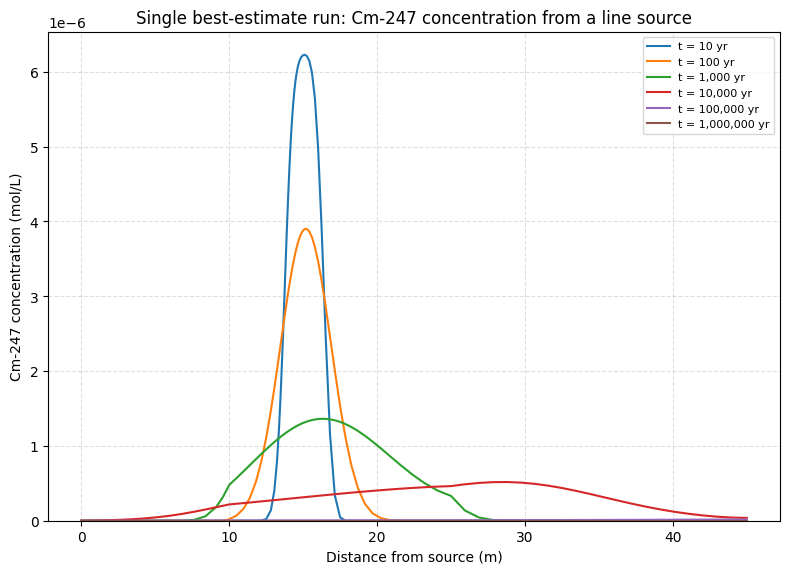

In [6]:
# Process and plot concentration profiles
nuclide_results = results[NUCLIDE_NAME]

PLOT_TIMES_YEARS = [10, 100, 1_000, 10_000, 100_000, 1_000_000]

plot_concentration_profile(
    nuclide_results,
    NUCLIDE_NAME,
    PLOT_TIMES_YEARS,
    title="Single best-estimate run: Cm-247 concentration from a line source",
)
plt.show()

### Discharge from the containment-providing rock zone vs. regulatory limits

Compares the single run's cumulative fraction discharged and release rate from the ewg (`total_frac_discharged`, `total_release_rate`) against the EndlSiAnfV limits.

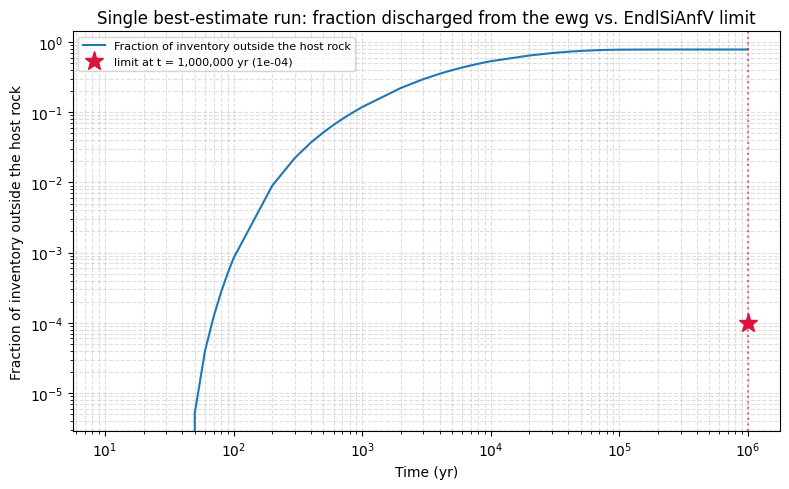

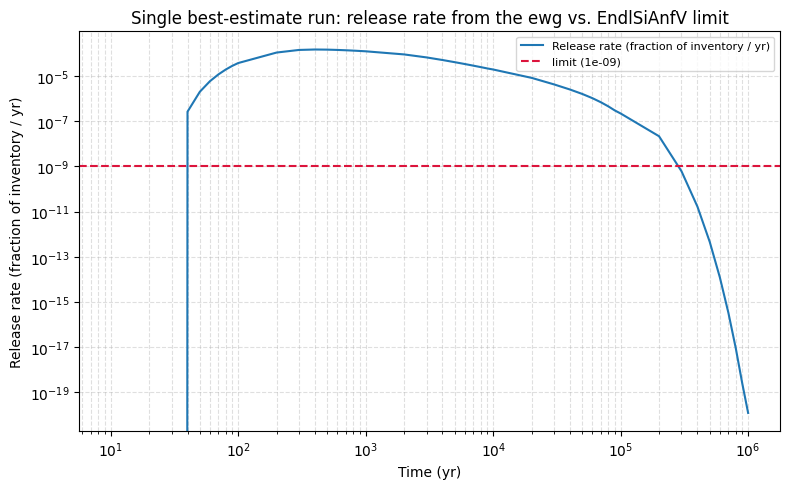

In [11]:
plot_discharge_vs_limit(
    results["total_frac_discharged"],
    ylabel="Fraction of inventory outside the host rock",
    limit_value=LIMIT_CUMULATIVE_1E6A,
    limit_time_years=LIMIT_TIME_YEARS,
    title="Single best-estimate run: fraction discharged from the ewg vs. EndlSiAnfV limit",
)
plt.show()

plot_discharge_vs_limit(
    results["total_release_rate"],
    ylabel="Release rate (fraction of inventory / yr)",
    limit_value=LIMIT_RATE_PER_A,
    title="Single best-estimate run: release rate from the ewg vs. EndlSiAnfV limit",
)
plt.show()

## 3. Ensemble run (uncertainty quantification)

Draws a small Sobol' ensemble over the 16 uncertain parameters, runs one OGS simulation per sample, and plots the ensemble mean and min-max band. Since the unit's thickness is itself uncertain, profiles are interpolated onto one common distance grid before the mean/min/max are computed.

In [12]:
! ./make_ensemble_samples.sh

In [13]:
! ./run_ensemble.sh

OGS samples:   0%|                                   | 0/8 [00:00<?, ?sample/s]Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : Meshing 1D...
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 30%] Meshing curve 4 (Line)
Info    : [ 30%] Meshing curve 5 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 30%] Meshing curve 4 (Line)
Info    : [ 30%] Meshing curve 5 (Line)
Info    : [ 40%] Meshing curve 6 (Line)
Info    : [ 40%] Meshing curve 6 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 50%] Meshing curve 8 (Line)
Info    : [ 50%] Meshing curve 8 (Line)
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 60%] Meshing curve 9 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 60%] Meshing curve 9 (Line)
Info    :

In [14]:
ENSEMBLE_OUTPUT_DIR = BASE_DIR / "output" / "ensemble_run"

# load results
results_file = max(ENSEMBLE_OUTPUT_DIR.glob("*.h5"), key=lambda p: p.stat().st_mtime)
ensemble_results = load_results_from_hdf5(str(results_file))["simulation_results"]

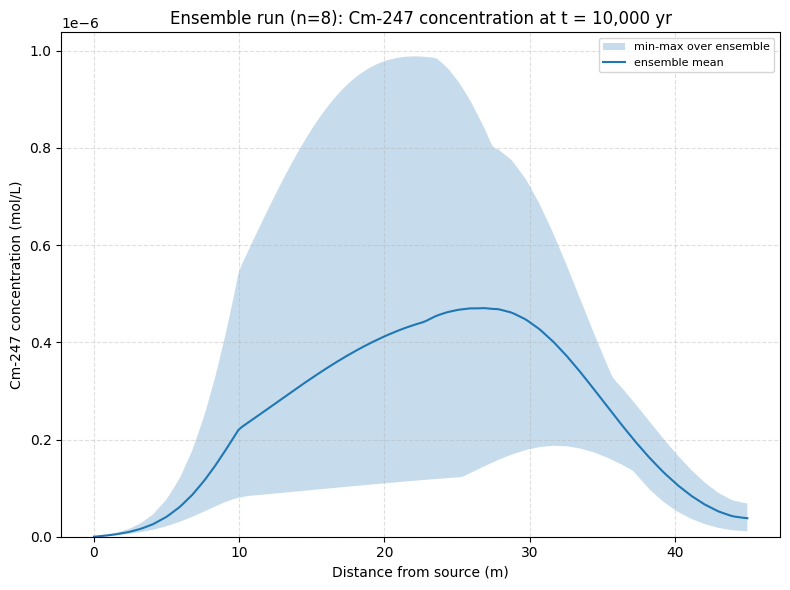

In [15]:
# Process and plot ensemble concentration profiles
nuclide_results = ensemble_results[NUCLIDE_NAME]
SOURCE_LOC = 0.0
PLOT_TIME_YEARS = 10_000

plot_ensemble_profile(
    nuclide_results,
    NUCLIDE_NAME,
    PLOT_TIME_YEARS,
    source_loc=SOURCE_LOC,
)
plt.show()

### Ensemble discharge vs. regulatory limits

Same comparison as above, now showing the ensemble mean and min-max band for `total_frac_discharged`/`total_release_rate`.

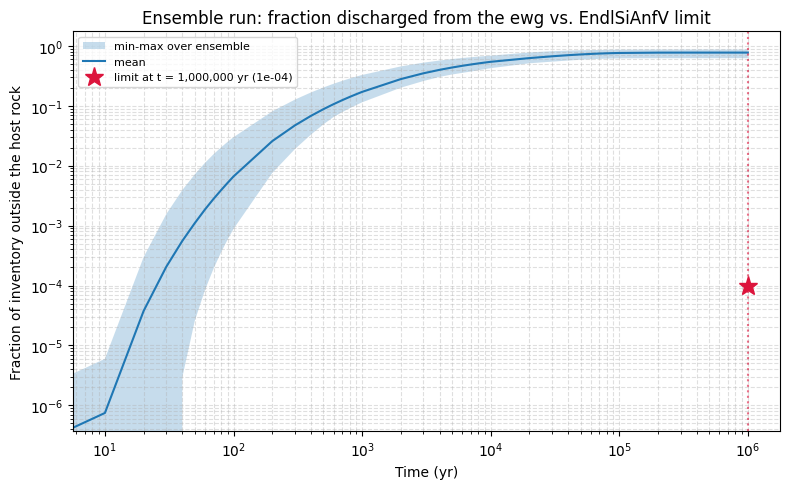

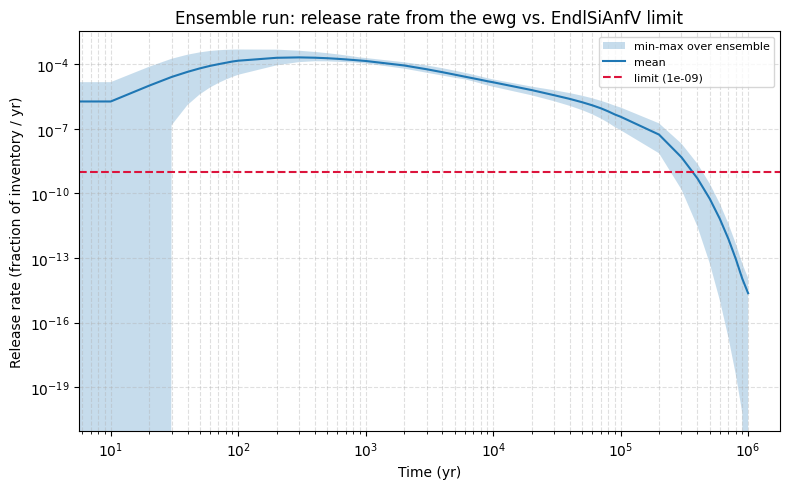

In [16]:
plot_discharge_vs_limit(
    ensemble_results["total_frac_discharged"],
    ylabel="Fraction of inventory outside the host rock",
    limit_value=LIMIT_CUMULATIVE_1E6A,
    limit_time_years=LIMIT_TIME_YEARS,
    title="Ensemble run: fraction discharged from the ewg vs. EndlSiAnfV limit",
)
plt.show()

plot_discharge_vs_limit(
    ensemble_results["total_release_rate"],
    ylabel="Release rate (fraction of inventory / yr)",
    limit_value=LIMIT_RATE_PER_A,
    title="Ensemble run: release rate from the ewg vs. EndlSiAnfV limit",
)
plt.show()